In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import PowerTransformer

In [2]:
df = pd.read_csv('IPLPlayerStat.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings,player_form,player_form_encoded
0,0,0,A Ashish Reddy,280,31,196,NaN,270,400,28,10.00,142.86,15.82,8.89,22.22,15.00,8,0,Poor,0
1,1,1,A Badoni,161,18,139,2.0,12,12,11,14.64,115.83,12.95,6.00,6.00,6.00,8,0,Average,1
2,2,2,A Chandila,4,0,7,11.0,234,245,12,0.33,57.14,0.00,6.28,22.27,21.27,2,0,Poor,0
3,3,3,A Chopra,53,7,75,0.0,0,0,6,8.83,70.67,9.33,0.00,0.00,0.00,2,0,Poor,0
4,4,4,A Choudhary,25,2,20,5.0,108,144,5,5.00,125.00,10.00,8.00,28.80,21.60,0,0,Poor,0


In [7]:
df['runs'].describe()

,runs
count,605.000000
mean,464.428099
std,985.272855
min,0.000000
25%,15.000000
50%,73.000000
75%,326.000000
max,6634.000000


right skewed data 



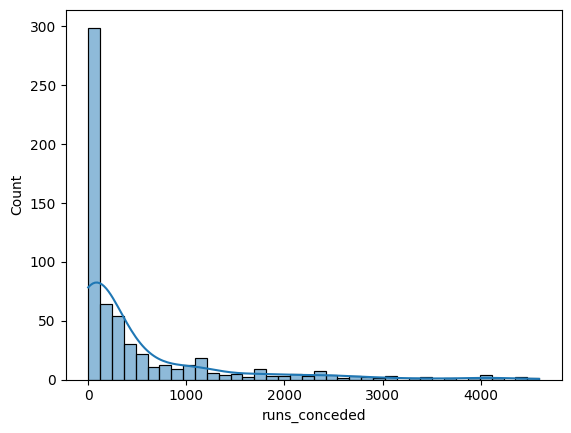

In [11]:
sns.histplot(
    df['runs_conceded'] ,
    kde = True
)

print("right skewed data \n")

Yeo Johnson method

y = [ (( x + 1 ) ^ lambda ) - 1 ]  / lambda  ........................ if lambda != 0
<br>
y = log(x+1) ............................ lambda = 0

In [17]:
pt = PowerTransformer(method = 'yeo-johnson')
df['runs_power'] = pt.fit_transform(
    df[['runs']]
)

print(pt.lambdas_)

[0.00085692]


<Axes: xlabel='runs_power', ylabel='Count'>

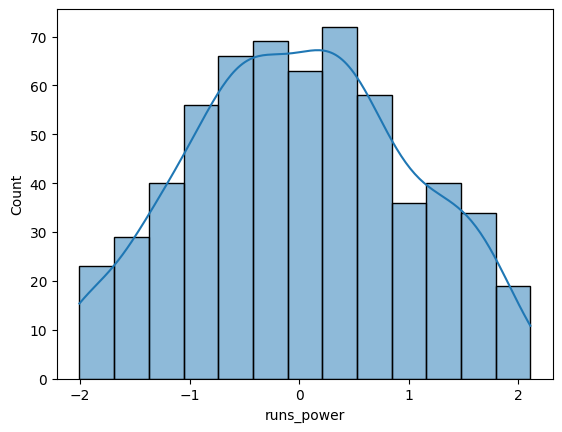

In [18]:
sns.histplot(
    df['runs_power'],
    kde = True ,
)

Box-Cox Method

y = [ (x ^ lambda ) - 1 ]  / lambda    ...........................  if lambda != 0
<br>
y = log(x) ................................................ if lambda = 0

In [22]:
pt = PowerTransformer(method = 'box-cox')
df['runs_power'] = pt.fit_transform(
    df[['runs']] + 0.00001
)

print(pt.lambdas_)

[0.1470304]


<Axes: xlabel='runs_power', ylabel='Count'>

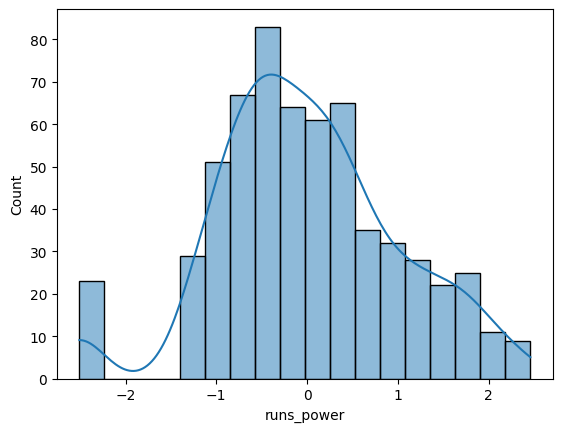

In [25]:
sns.histplot(
    df['runs_power'],
    kde = True ,
)